# MG near-null space evolution under HMC

How does a multigrid near-null (deflation) basis go stale as the gauge field evolves under HMC, and how cheaply can it be kept current? This notebook collects the trajectory-length sweep run with `Grid/examples/Example_mg_evolution.cc` on SDCC (jobs 424665 and 424793–424796, 2026-10-20 to 2026-10-21), defines every quantity it uses, and states what the sweep does and does not show.

**Headline.** For gauge-field displacements up to $d_U \approx 0.05$ the fraction of the near-null space that a frozen basis loses is $1 - c_{\rm frozen} \approx 1.8\, d_U$, the same in every run regardless of trajectory length. Above that it bends over and saturates; one full $\tau = 1$ trajectory already reaches $d_U \approx 0.6$ and loses about 70%. A single sloppy refresh per trajectory recovers most of the loss.

## 1. Definitions

Every symbol in the text and every variable in the code is defined here. The *code name* column is the name used in the code cells (and, where it differs, the column of the `MGEVO-SUMMARY` log line).

### Operator and evolution

| Symbol | Code name | Definition |
|---|---|---|
| $A$ | — | The operator whose near-null space is studied: $A = D_{\rm PV}^\dagger D_{\rm DW}(m)$, Pauli–Villars preconditioned Möbius domain wall, $L_s = 16$, $M_5 = 1.8$, $b = 1.5$, $c = 0.5$, $m = 0.001$, PV mass 1. |
| $U_0$ | — | Starting gauge field, `ckpoint_lat.4000`, $16^3 \times 32$. |
| $U_t$ | — | Gauge field after $t$ HMC trajectories. |
| $t$ | `traj` | Trajectory index, $t = 1, \dots, 10$. |
| $\tau$ | `trajL` | Trajectory length in MD time. The sweep variable: $\tau \in \{0.01, 0.03, 0.1, 0.3, 1\}$. |
| $N_{\rm MD}$ | `MDsteps` | MD steps per trajectory, $\max(4, \mathrm{round}(80\tau))$, MinimumNorm2 integrator. |
| $\delta\tau$ | — | MD step size $\tau / N_{\rm MD}$; $1/80$ except at $\tau \le 0.03$, where the floor of 4 steps makes it smaller. |
| $\beta$ | — | Quenched Iwasaki coupling used for the evolution, $2.13$ (a guess; see caveats). |
| $\Delta H$ | — | Energy violation of a trajectory; Metropolis test on. |
| $P_{\rm acc}$ | `p_acc` | Expected acceptance of a run, $\langle \min(1, e^{-\Delta H}) \rangle$ over its trajectories. |
| $d_U(t)$ | `dU` | Gauge distance from the start, averaged over links: $d_U = 1 - \langle \mathrm{Re}\, \mathrm{tr}(U_0^\dagger U_t) \rangle / N_c$. Zero at $t = 0$, about 1 for unrelated fields. **Not gauge invariant.** See *Gauge distance* below. |
| $\Delta d_U$ | `dU_traj1` | $d_U$ after the first trajectory, i.e. the displacement produced by one trajectory of length $\tau$. |

### Bases

| Symbol | Code name | Definition |
|---|---|---|
| $N$ | `nbasis` | Vectors per basis, $N = 8$. |
| $S_0$ | — | Basis bred at $U_0$: each vector is Gaussian noise passed three times through unpreconditioned GCR inverse iteration on $A$ (`CreateSubspaceGCR`). Never changed afterwards: the **frozen** basis. |
| $S_t^{\rm fresh}$ | — | Basis re-bred at $U_t$ from **the same noise** as $S_0$ (the breeding RNG is re-seeded identically), so it differs from $S_0$ only through the operator. The reference for "where the near-null space is now". |
| $S_t^{\rm refined}$ | — | $S_{t-1}^{\rm refined}$ after one sloppy GCR inverse-iteration pass with $A(U_t)$ (tolerance $10^{-2}$, at most 2 restarts of GCR(10)); $S_0^{\rm refined} = S_0$. The cheap per-trajectory refresh. |
| block | — | One aggregate of the coarse grid: $2^4$ sites in the 4d volume times all of $L_s$, so $2^4 \times 16 \times 12 = 3072$ complex degrees of freedom. |
| $\mathcal{B}(S)$ | — | **Block span** of $S$: the span of the restrictions of its $N$ vectors to each block, i.e. $N$ dimensions per block. This is the coarse space the MG preconditioner actually uses. |
| $P_S$ | — | Orthogonal projector onto $\mathcal{B}(S)$, computed as `PromoteFromSubspace` ∘ `ProjectToSubspace` on the block-orthonormalised basis. |

### Measurements

| Symbol | Code name | Definition |
|---|---|---|
| $f_S(w)$ | — | Captured fraction of a vector $w$ by the block span of $S$: $f_S(w) = \lVert P_S w \rVert^2 / \lVert w \rVert^2$. |
| $c(S)$ | — | Capture of the current near-null space by $S$: the mean of $f_S(w)$ over the $N$ vectors $w$ of $S_t^{\rm fresh}$. |
| $c_{\rm frozen}$ | `cap_f` | $c(S_0)$: how much of today's near-null space the original coarse space still holds. |
| $c_{\rm refined}$ | `cap_r` | $c(S_t^{\rm refined})$: whether the cheap refresh keeps up. |
| $c_{\rm step}$ | `cap_s` | $c(S_{t-1}^{\rm fresh})$: how much one trajectory moves the near-null space. |
| $c_{\rm self}$ | `cap_self` | $c(S_t^{\rm fresh})$: self-check, must be 1. |
| $1 - c$ | `loss_f`, `loss_r`, `loss_s` | **Capture loss**, the plotted quantity. |
| $k$ | `k_fit` | Slope of $1 - c_{\rm frozen}$ against $d_U$ in the linear regime (least squares through the origin, $d_U < 0.05$). |
| $c_{\rm ceil}$ | `cap_other` | Same-$U$ ceiling: capture at $U_0$ of a basis bred from *different* noise, by $\mathcal{B}(S_0)$. Measured $0.927$, so a loss of $0.073$ is what changing the noise alone costs. |
| $c_{\rm floor}$ | `cap_random` | Capture at $U_0$ of Gaussian vectors by $\mathcal{B}(S_0)$. Measured $0.0026$, matching $N / 3072$. |
| $\theta_k$ | — | Principal angles between the **global** spans of two bases, $k = 1, \dots, N$; see *Principal angles* below. |
| $\mathrm{dist}^2$ | `d_flow`, `d_step` | $\sum_k \sin^2\theta_k \in [0, N]$, for $S_0$ vs $S_t^{\rm fresh}$ (`d_flow`) and $S_{t-1}^{\rm fresh}$ vs $S_t^{\rm fresh}$ (`d_step`). $N = 8$ means fully orthogonal. |
| $\eta(S)$ | `eta_f`, `eta_r`, `eta_fr` | Nulliness of the global span: $\mathrm{tr}(V^\dagger A^\dagger A V)/N$ for orthonormal $V$ spanning $S$. Logged but not used below. |

### Gauge distance $d_U$

For $SU(N_c)$ link matrices $\lVert U_t - U_0 \rVert_F^2 = 2N_c - 2\,\mathrm{Re}\,\mathrm{tr}(U_0^\dagger U_t)$, so

$$d_U = \frac{1}{2N_c} \big\langle \lVert U_t(x,\mu) - U_0(x,\mu) \rVert_F^2 \big\rangle_{x,\mu},$$

the mean squared chordal (Frobenius) distance per link, normalised. It is computed in `LinkDistance` from one `sum(trace(adj(U_0) U_t))` per direction. For a small change $U_t = e^{i\epsilon X} U_0$ it expands as $d_U \approx \epsilon^2\, \mathrm{tr}(X^2) / (2N_c)$: **quadratic in the link displacement**, the same order as a capture loss $1 - \cos^2\theta \approx \theta^2$, which is what makes a linear relation between the two meaningful. It is not gauge invariant: a gauge transformation of $U_t$ alone changes $d_U$ without changing any physics, and it weights every link equally whatever its effect on $A$.

### Principal angles $\theta_k$ and $\mathrm{dist}^2$

For two $N$-dimensional subspaces $\mathcal{A}$ and $\mathcal{B}$ the principal angles $0 \le \theta_1 \le \dots \le \theta_N \le \pi/2$ are defined greedily: $\cos\theta_1 = \max |\langle a | b \rangle|$ over unit vectors $a \in \mathcal{A}$, $b \in \mathcal{B}$, then $\cos\theta_2$ is the same maximum over vectors orthogonal to the first pair, and so on. The modulus makes complex phases irrelevant.

- They depend only on the spans, not on the vectors representing them: any invertible change of basis within $\mathcal{A}$ or $\mathcal{B}$ leaves them unchanged.
- All $\theta_k = 0$: identical spans. All $\theta_k = \pi/2$: orthogonal spans. In general the number of zero angles is $\dim(\mathcal{A} \cap \mathcal{B})$; a nonzero angle below $\pi/2$ is a pair of directions that partly overlap.

**Computation** (`ReportAngles` in the example), without orthonormalising any lattice vectors. With $A$ and $B$ the matrices whose columns are the stored basis vectors, form the Gram matrices and the cross matrix,

$$G_A = A^\dagger A, \qquad G_B = B^\dagger B, \qquad C = A^\dagger B,$$

which costs about $2N^2$ inner products. Cholesky-factor $G_A = L_A L_A^\dagger$ and $G_B = L_B L_B^\dagger$; then $Q_A = A L_A^{-\dagger}$ and $Q_B = B L_B^{-\dagger}$ are orthonormal bases of the two spans, and

$$Q_A^\dagger Q_B = L_A^{-1}\, C\, L_B^{-\dagger}, \qquad \cos\theta_k = \sigma_k\big(L_A^{-1} C L_B^{-\dagger}\big),$$

the singular values of an $N \times N$ matrix.

**Distance.** The summary used in the plots is

$$\mathrm{dist}^2 = \sum_{k=1}^N \sin^2\theta_k = N - \lVert Q_A^\dagger Q_B \rVert_F^2 = \tfrac{1}{2} \lVert P_{\mathcal{A}} - P_{\mathcal{B}} \rVert_F^2 \in [0, N],$$

half the squared Frobenius distance between the two orthogonal projectors. Unlike $\theta_{\max}$, which pins at $\pi/2$ as soon as one direction has rotated fully away, it keeps grading the separation. It is also the global-span version of capture: averaging the captured fraction of an orthonormal basis of $\mathcal{B}$ by $\mathcal{A}$ gives $\frac{1}{N}\sum_k \cos^2\theta_k = 1 - \mathrm{dist}^2/N$. The block-span capture $c$ asks the same question of $\mathcal{B}(S)$, which contains the global span of $S$ and has $N$ dimensions per block, so it saturates far later.

### MG solves

| Symbol | Code name | Definition |
|---|---|---|
| rung (b) | `rb`, `sb` | Two-level MG with $S_0$, coarse operator rebuilt at $U_t$ ("recoarsen"). |
| rung (c) | `rc`, `sc` | Two-level MG with $S_t^{\rm refined}$, coarse operator rebuilt at $U_t$. |
| rung (d) | `rd`, `sd` | Two-level MG with $S_t^{\rm fresh}$: setup from scratch at $U_t$, the baseline. |
| relres | `rb`, `rc`, `rd` | True relative residual $\lVert b - A x \rVert / \lVert b \rVert$ of the outer flexible GCR(16) solve of $A x = b$ (fixed Gaussian $b$), after at most 208 outer steps. At $N = 8$ **every** solve hits the 208-step cap, so relres at the cap is the figure of merit, not the step count `sb`, `sc`, `sd`. |

### Code variables

| Code name | Definition |
|---|---|
| `LOG_DIR` | Directory holding the run logs, `../logs/ckpoint_lat.4000` relative to this notebook. |
| `RUNS` | Map $\tau \mapsto$ job ID for the five runs. |
| `SCAN` | Map $N_{\rm MD} \mapsto$ job ID for the acceptance scan at $\tau = 1$ (section 9). |
| `scan` | Map $N_{\rm MD} \mapsto$ table of that scan run's trajectories, as in `runs`; $N_{\rm MD} = 80$ is the sweep's $\tau = 1$ run. |
| `acc_table` | Acceptance summary per $N_{\rm MD}$ (section 9). |
| `moved` | Rows of a scan run with $d_U > 0$, i.e. after the first accepted trajectory. |
| `PRE_FIX` | Values of $\tau$ whose rung (c) predates the seeding fix: $\{0.01\}$. |
| `DU_LINEAR_MAX` | Upper end of the linear regime used to fit $k$: $d_U < 0.05$. |
| `runs` | Map $\tau \mapsto$ table of that run's trajectories, one row per $t$, columns as in the tables above plus `trajL`, `dH`, `accepted` (Metropolis outcome), `loss_f`, `loss_r`, `loss_s`. |
| `data` | All runs' rows concatenated. |
| `md_time` | Cumulative MD time $t\tau$ after trajectory $t$ (a column of every run's table). |
| `post` | `data` without the `PRE_FIX` runs; used wherever rung (c) is plotted. |
| `controls` | Map $\tau \mapsto$ the $t = 0$ captures `self`, `other`, `random` of that run. |
| `cap_other`, `cap_random` | $c_{\rm ceil}$ and $c_{\rm floor}$, averaged over the five (identical) runs. |
| `block_dof` | Complex degrees of freedom per block, $3072$. |
| `checks` | The sanity-check table of section 3. |
| `linear_regime` | Rows of `data` with $d_U <$ `DU_LINEAR_MAX`. |
| `k_fit` | $k$, the fitted slope (section 1). |
| `ratio_table` | $(1 - c_{\rm frozen}) / d_U$ for every trajectory, by run. |
| `first` | $\Delta d_U$ per run: $d_U$ after the first trajectory (column `dU_traj1`). |
| `small_tau` | The rows of `first` with $\tau \le 0.3$, used for the fit. |
| `p_fit`, `logc_fit` | Exponent and log-prefactor of the fit $\Delta d_U = e^{\rm logc\_fit}\, \tau^{\rm p\_fit}$ over $\tau \le 0.3$. |
| `final_traj` | Rows of `post` at the last trajectory, $t = 10$. |
| `series` | The (rung, legend label, table, residual column) entries plotted in section 7. |
| `x_grid`, `tau_grid` | Plotting grids for the reference lines. |
| `pt`, `fmt` | The user's plotting library `plottools` and its style module `formattools`, from `/Users/patrickoare/lqcd/utilities`. All figures use `fmt.default_style` (the `notebook` style). |
| `CMAP`, `NORM`, `TRAJL_COLOR` | Colour per run: $\tau$ is ordered, so run $i$ gets `plasma` at `NORM(i)`. |
| `RUNG_COLOR`, `RUNG_MARKER` | Colour (`pt.pal`) and marker per MG rung. |
| `REF_COLOR` | Colour of reference lines, `pt.pal[7]`. |
| `LEGEND` | Legend placement and font sizes shared by every figure. |
| `labels` | Axis labels shared by the two series of the section 6 figure. |

## 2. What one run does

Each run starts from $U_0$, breeds $S_0$, and records the controls $c_{\rm self}$, $c_{\rm ceil}$ and $c_{\rm floor}$. Then for each of 10 trajectories:

1. Run one HMC trajectory of length $\tau$ (quenched Iwasaki, Metropolis on) and record $d_U(t)$.
2. Re-breed $S_t^{\rm fresh}$ from the same noise as $S_0$, and refresh $S_t^{\rm refined}$ with one sloppy pass.
3. Record the global-span measurements ($\theta_k$, $\mathrm{dist}^2$, $\eta$) on the bases as bred.
4. Run the three MG solves (b), (c), (d), each with its coarse operator rebuilt at $U_t$.
5. Record the block-span captures $c_{\rm frozen}$, $c_{\rm refined}$, $c_{\rm step}$, $c_{\rm self}$.

| $\tau$ | $N_{\rm MD}$ | job | log file |
|---|---|---|---|
| 0.01 | 4 | 424665 | `MG_evolution_trajL0.01_424665.log` |
| 0.03 | 4 | 424793 | `MG_evolution_trajL0.03_424793.log` |
| 0.1 | 8 | 424794 | `MG_evolution_trajL0.1_424794.log` |
| 0.3 | 24 | 424795 | `MG_evolution_trajL0.3_424795.log` |
| 1.0 | 80 | 424796 | `MG_evolution_trajL1.0_424796.log` |

**The $\tau = 0.01$ run used rung (c) before a seeding fix.** It refreshed the block-orthonormalised copy of the refined basis, which drifts away from the near-null space; from $t = 2$ its $c_{\rm refined}$ is not comparable with the other runs and is excluded from the rung (c) plots below. Everything else in that run is unaffected.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

sys.path.append('/Users/patrickoare/lqcd/utilities')
import plottools as pt
import formattools as fmt

# Logs as copied from SDCC; the notebook lives in lqcd/multigrid/python_scripts
LOG_DIR = Path("../logs/ckpoint_lat.4000")

# trajL -> job ID, the five runs of the sweep
RUNS = {0.01: 424665, 0.03: 424793, 0.1: 424794, 0.3: 424795, 1.0: 424796}

# MD steps -> job ID, the acceptance scan at trajL = 1 (section 9)
SCAN = {30: 425356, 40: 425357, 50: 425358}

# trajL whose rung (c) predates the seeding fix (see section 2)
PRE_FIX = {0.01}

# Linear-regime cut for the slope fit k
DU_LINEAR_MAX = 0.05

# Colours: trajL is ordered, so it runs along a colormap; the rungs are categories
CMAP = mpl.colormaps['plasma']
NORM = mpl.colors.Normalize(vmin=0, vmax=len(RUNS))    # vmax past the last run keeps it off the pale end
TRAJL_COLOR = {trajL: CMAP(NORM(i)) for i, trajL in enumerate(RUNS)}
RUNG_COLOR  = {"(b) frozen S0": pt.pal[0], "(c) refined": pt.pal[1], "(d) fresh": pt.pal[2]}
RUNG_MARKER = {"(b) frozen S0": "o", "(c) refined": "s", "(d) fresh": "^"}
REF_COLOR   = pt.pal[7]                                 # reference lines and their labels

# Legend placement and size used throughout
LEGEND = dict(title_fontsize=fmt.default_style['fontsize'], fontsize=fmt.default_style['fontsize'],
              bbox_to_anchor=(1, 1), loc='upper left')

In [2]:
# Columns of an MGEVO-SUMMARY line, in order (names as in section 1)
SUMMARY_COLS = ["traj", "plaq", "dU", "cap_f", "cap_r", "cap_s", "cap_self",
                "th_flow", "th_step", "th_ref", "d_flow", "d_step", "d_ref",
                "eta_f", "eta_r", "eta_fr", "sb", "sc", "sd", "rb", "rc", "rd"]

def log_path(trajL, job):
    return LOG_DIR / f"MG_evolution_trajL{trajL}_{job}.log"

def read_run(trajL, job, path=None):
    # One row per trajectory from the MGEVO-SUMMARY lines, plus the t = 0 controls
    rows, controls, dH, accepted = [], {}, [], []
    for line in open(path or log_path(trajL, job), errors="replace"):
        if "MGEVO-SUMMARY" in line:
            vals = line.split("MGEVO-SUMMARY")[1].split()
            rows.append(dict(zip(SUMMARY_COLS, map(float, vals))))
        m = re.search(r"MGEVO-CAPTURE traj 0 (self|other|random).* mean (\S+)", line)
        if m:
            controls[m.group(1)] = float(m.group(2))
        m = re.search(r"dH = (\S+)", line)
        if m:
            dH.append(float(m.group(1)))
        if "Metropolis_test --" in line:
            accepted.append("ACCEPTED" in line)
    df = pd.DataFrame(rows)
    df["traj"] = df["traj"].astype(int)
    df["trajL"] = trajL
    df["dH"] = dH[:len(df)]
    df["accepted"] = accepted[:len(df)]
    df["loss_f"] = 1.0 - df["cap_f"]
    df["loss_r"] = 1.0 - df["cap_r"]
    df["loss_s"] = 1.0 - df["cap_s"]
    df["md_time"] = df["traj"] * trajL
    return df, controls

runs, controls = {}, {}
for trajL, job in RUNS.items():
    runs[trajL], controls[trajL] = read_run(trajL, job)

data = pd.concat(runs.values(), ignore_index=True)
print(f"{len(data)} trajectories from {len(runs)} runs")

# MD-step scan at trajL = 1 (section 9); 80 steps is the sweep's tau = 1 run
scan = {n_md: read_run(1.0, job, LOG_DIR / f"MG_evolution_trajL1.0_md{n_md}_{job}.log")[0]
        for n_md, job in SCAN.items()}
scan[80] = runs[1.0]
print("scan:", {n: len(df) for n, df in scan.items()})

50 trajectories from 5 runs


scan: {30: 10, 40: 10, 50: 10, 80: 10}


## 3. Sanity checks

The controls at $U_0$ must be identical in every run (same configuration, same noise): $c_{\rm self} = 1$, $c_{\rm ceil} \approx 0.927$, $c_{\rm floor} \approx N/3072 = 0.0026$. $\Delta H$ should be small and $c_{\rm self}$ should stay 1 along every run.

In [3]:
cap_other  = np.mean([c["other"]  for c in controls.values()])
cap_random = np.mean([c["random"] for c in controls.values()])
nbasis, block_dof = 8, 2**4 * 16 * 12

checks = pd.DataFrame({
    "cap_self (t=0)":    [controls[t]["self"]   for t in RUNS],
    "cap_other (t=0)":   [controls[t]["other"]  for t in RUNS],
    "cap_random (t=0)":  [controls[t]["random"] for t in RUNS],
    "max |dH|":          [runs[t]["dH"].abs().max() for t in RUNS],
    "accepted":          [f'{int(runs[t]["accepted"].sum())}/{len(runs[t])}' for t in RUNS],
    "p_acc":             [np.minimum(1.0, np.exp(-runs[t]["dH"])).mean() for t in RUNS],
    "min cap_self (t>0)":[runs[t]["cap_self"].min() for t in RUNS],
    "plaquette t=10":    [runs[t]["plaq"].iloc[-1] for t in RUNS],
}, index=pd.Index(list(RUNS), name="trajL"))
print(f"floor expected N/block_dof = {nbasis/block_dof:.5f}")
checks

floor expected N/block_dof = 0.00260


,cap_self (t=0),cap_other (t=0),cap_random (t=0),max |dH|,accepted,p_acc,min cap_self (t>0),plaquette t=10
trajL,,,,,,,,
0.01,1.0,0.926652,0.002604,0.000188,10/10,0.999935,1.0,0.587617
0.03,1.0,0.926652,0.002604,0.004956,10/10,0.998572,1.0,0.587506
0.10,1.0,0.926652,0.002604,0.040076,10/10,0.990406,1.0,0.587099
0.30,1.0,0.926652,0.002604,0.070850,10/10,0.973983,1.0,0.585184
1.00,1.0,0.926652,0.002604,0.324784,10/10,0.901250,1.0,0.579622


All controls agree across the five runs, $c_{\rm floor}$ matches $N/3072$, and $c_{\rm self}$ stays 1. Every run accepted all 10 trajectories. The expected acceptance $P_{\rm acc}$ falls from 1.00 at $\tau = 0.01$ to 0.90 at $\tau = 1$; with 10 trajectories, all ten being accepted at $\tau = 1$ had probability about 0.34, so it is a fortunate draw rather than evidence that the integrator is better than $P_{\rm acc}$ says. The $\tau = 1$ run repeats job 424581 exactly (same seeds, identical $\Delta H$ sequence). The plaquette moves by less than $6 \times 10^{-4}$ for $\tau \le 0.1$ but drifts down for $\tau \ge 0.3$ (from 0.5877 to 0.5796 at $\tau = 1$): there the evolution includes relaxation towards quenched Iwasaki at the guessed $\beta$, not only equilibrium fluctuation.

## 4. Result: capture loss depends on $d_U$ alone

The plot below puts every trajectory of every run on one axis. If staleness were governed by something other than how far $U$ has moved — the number of trajectories, momentum refreshes, the trajectory length — the five runs would sit on different curves.

slope k = 1.818 from 24 trajectories with d_U < 0.05


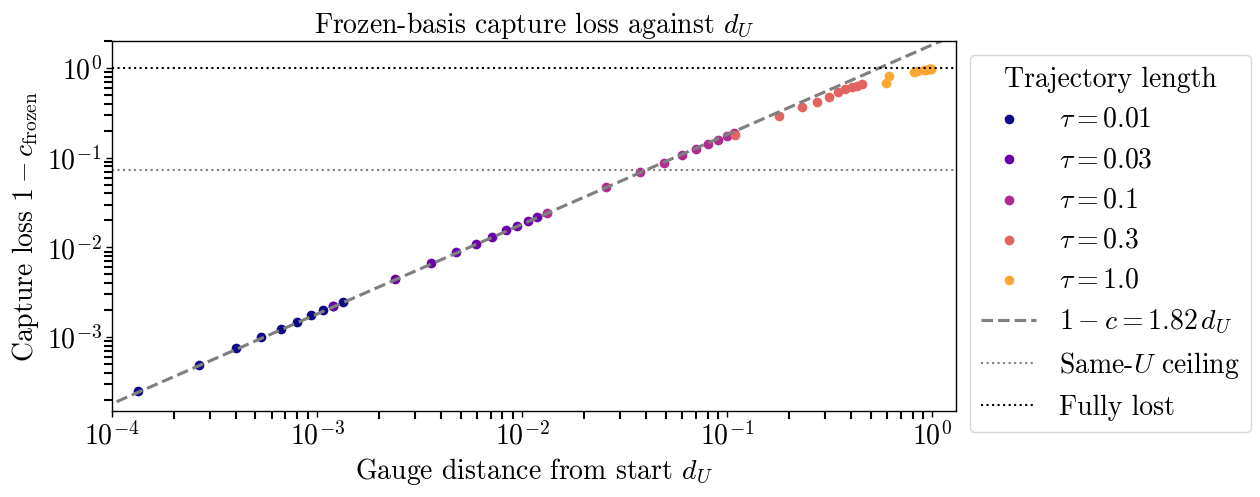

In [4]:
linear_regime = data[data["dU"] < DU_LINEAR_MAX]
k_fit = float((linear_regime["loss_f"] * linear_regime["dU"]).sum() / (linear_regime["dU"] ** 2).sum())
print(f"slope k = {k_fit:.3f} from {len(linear_regime)} trajectories with d_U < {DU_LINEAR_MAX}")

fig, ax = pt.add_subplots()
ax = ax[0]
x_grid = np.logspace(-4.2, 0.1, 100)
for trajL, df in runs.items():
    pt.scatter_1d(df["dU"], df["loss_f"], ax=ax, col=TRAJL_COLOR[trajL], mkr='o',
                  fn_label=rf"$\tau = {trajL}$", logx=True, logy=True,
                  ax_label=[r"Gauge distance from start $d_U$", r"Capture loss $1 - c_{\rm frozen}$"])
pt.plot_1d_data(x_grid, k_fit * x_grid, ax=ax, col=[REF_COLOR], linestyle='--',
                fn_label=rf"$1 - c = {k_fit:.2f}\, d_U$", logy=True,
                ax_label=[r"Gauge distance from start $d_U$", r"Capture loss $1 - c_{\rm frozen}$"])
pt.add_line(ax, 1 - cap_other, orientation='h', c=REF_COLOR, linestyle=':', label='Same-$U$ ceiling')
pt.add_line(ax, 1.0, orientation='h', c='k', linestyle=':', label='Fully lost')
ax.set_xlim(1e-4, 1.3); ax.set_ylim(1.5e-4, 2)
pt.add_title(ax, r"Frozen-basis capture loss against $d_U$")
ax.legend(title=r"Trajectory length", **LEGEND)
plt.show()

In [5]:
# The same numbers as a table: ratio (1 - c_frozen) / d_U per run
ratio_table = data.assign(ratio=data["loss_f"] / data["dU"]).pivot(index="traj", columns="trajL", values="ratio")
ratio_table.round(2)

trajL,0.01,0.03,0.10,0.30,1.00
traj,,,,,
1,1.89,1.88,1.85,1.63,1.16
2,1.85,1.85,1.82,1.62,1.33
3,1.88,1.88,1.83,1.60,1.11
4,1.86,1.86,1.80,1.55,1.11
5,1.85,1.85,1.79,1.54,1.04
6,1.87,1.86,1.77,1.55,1.03
7,1.89,1.87,1.77,1.54,1.01
8,1.87,1.86,1.76,1.51,1.00
9,1.85,1.84,1.74,1.48,0.99


**Why $d_U$ and not MD time.** The same data against cumulative MD time $t\tau$, the more familiar axis, do not collapse: within a trajectory $U$ moves ballistically ($d_U \propto \tau^2$), but every trajectory redraws the momenta, so across trajectories $U$ random-walks ($d_U \propto t$). At equal MD time, short trajectories have moved $U$ far less. At $t\tau = 0.1$, ten trajectories of $\tau = 0.01$ reach $d_U = 1.3 \times 10^{-3}$ and lose 0.25% of capture, while one trajectory of $\tau = 0.1$ reaches $d_U = 1.3 \times 10^{-2}$ and loses 2.4%.

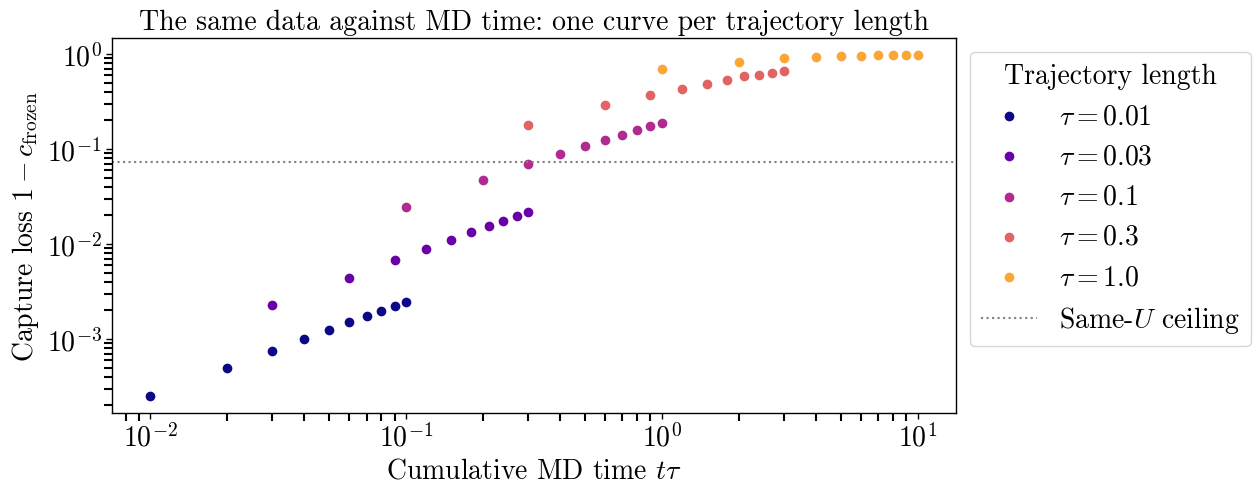

In [6]:
fig, ax = pt.add_subplots()
ax = ax[0]
for trajL, df in runs.items():
    pt.scatter_1d(df["md_time"], df["loss_f"], ax=ax, col=TRAJL_COLOR[trajL], mkr='o',
                  fn_label=rf"$\tau = {trajL}$", logx=True, logy=True,
                  ax_label=[r"Cumulative MD time $t\tau$", r"Capture loss $1 - c_{\rm frozen}$"])
pt.add_line(ax, 1 - cap_other, orientation='h', c=REF_COLOR, linestyle=':', label='Same-$U$ ceiling')
pt.add_title(ax, r"The same data against MD time: one curve per trajectory length")
ax.legend(title=r"Trajectory length", **LEGEND)
plt.show()

Within one trajectory, where $U$ does move ballistically, the two axes are tied by the law of section 5: $d_U \approx 1.3\, \Delta\tau^2$ after MD time $\Delta\tau$, so $1 - c_{\rm frozen} \approx 2.4\, \Delta\tau^2$ for $\Delta\tau \lesssim 0.2$. That is the form to use when choosing how often to update a basis along a trajectory; $d_U$ is the variable that explains why one law covers every trajectory length.

**What this shows.**

- Up to $d_U \approx 0.05$, $1 - c_{\rm frozen} = k\, d_U$ in every run with points there ($\tau = 0.01$, $0.03$, $0.1$): the ratio stays between 1.80 and 1.89 over a factor of almost 400 in $d_U$ (table above), and the fit gives the $k$ printed with the plot.
- Above that the curve bends over ($k$ falls to about 1.5 at $d_U \approx 0.45$) and saturates as $d_U \to 1$, where the frozen basis captures only 2.6% of the current near-null space, ten times the random floor.
- The frozen basis crosses the same-$U$ ceiling — the loss incurred simply by breeding from different noise — at $d_U \approx 0.04$.

**What it does not show.** The collapse is over one configuration, one noise seed for the reference, $N = 8$, and quenched dynamics. And $d_U$ is not gauge invariant, so part of what it measures (and part of the capture loss) may be pure gauge drift; see section 8.

## 5. How far one trajectory moves $U$

d_U after one trajectory ~ trajL^1.97 for trajL <= 0.3


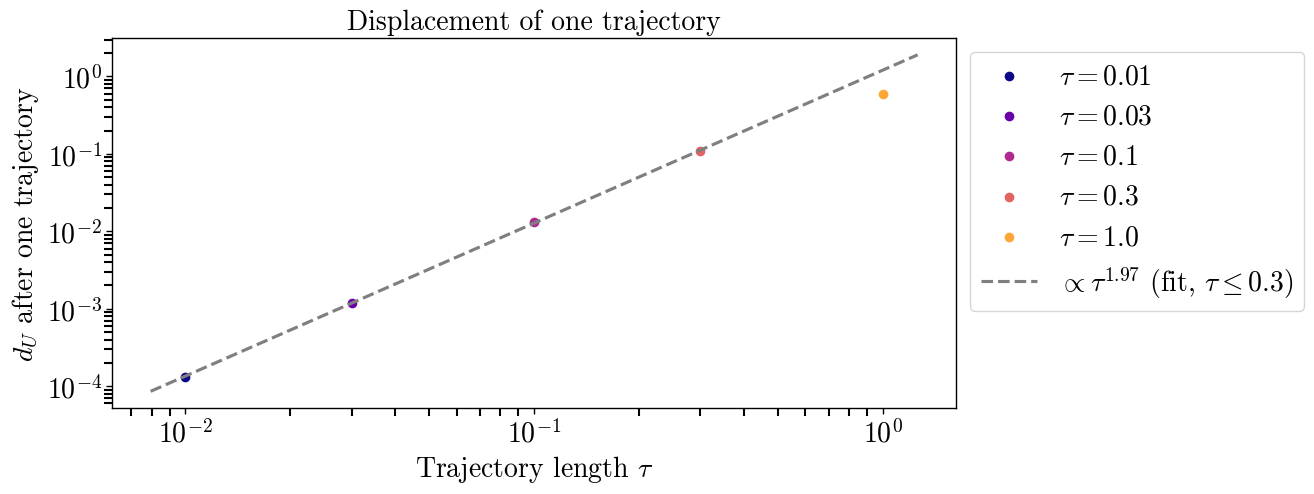

,dU_traj1
trajL,
0.01,0.000133
0.03,0.001198
0.10,0.013183
0.30,0.109325
1.00,0.592291


In [7]:
first = data[data["traj"] == 1][["trajL", "dU"]].rename(columns={"dU": "dU_traj1"})
small_tau = first[first["trajL"] <= 0.3]
p_fit, logc_fit = np.polyfit(np.log(small_tau["trajL"]), np.log(small_tau["dU_traj1"]), 1)
print(f"d_U after one trajectory ~ trajL^{p_fit:.2f} for trajL <= 0.3")

fig, ax = pt.add_subplots()
ax = ax[0]
tau_grid = np.logspace(-2.1, 0.1, 50)
for trajL in RUNS:
    row = first[first["trajL"] == trajL]
    pt.scatter_1d(row["trajL"], row["dU_traj1"], ax=ax, col=TRAJL_COLOR[trajL], mkr='o',
                  fn_label=rf"$\tau = {trajL}$", logx=True, logy=True,
                  ax_label=[r"Trajectory length $\tau$", r"$d_U$ after one trajectory"])
pt.plot_1d_data(tau_grid, np.exp(logc_fit) * tau_grid**p_fit, ax=ax, col=[REF_COLOR], linestyle='--',
                fn_label=rf"$\propto \tau^{{{p_fit:.2f}}}$ (fit, $\tau \leq 0.3$)", logy=True,
                ax_label=[r"Trajectory length $\tau$", r"$d_U$ after one trajectory"])
pt.add_title(ax, r"Displacement of one trajectory")
ax.legend(**LEGEND)
plt.show()
first.set_index("trajL")

Up to $\tau = 0.3$, $\Delta d_U \propto \tau^2$: within a trajectory $U$ moves ballistically, so $d_U$, which is quadratic in a small link rotation, grows as $\tau^2$. At $\tau = 1$ it reaches 0.6, well past the linear regime of section 4. Across trajectories (each with a fresh momentum draw) $U$ random-walks instead, and $d_U$ grows linearly in $t$, which is why the points of each run in section 4 are evenly spaced in $d_U$ at small $\tau$.

## 6. The cheap refresh, rung (c)

Capture loss of the refined basis against the frozen one, on the same $d_U$ axis. The $\tau = 0.01$ run is left out (pre-fix rung (c), section 2).

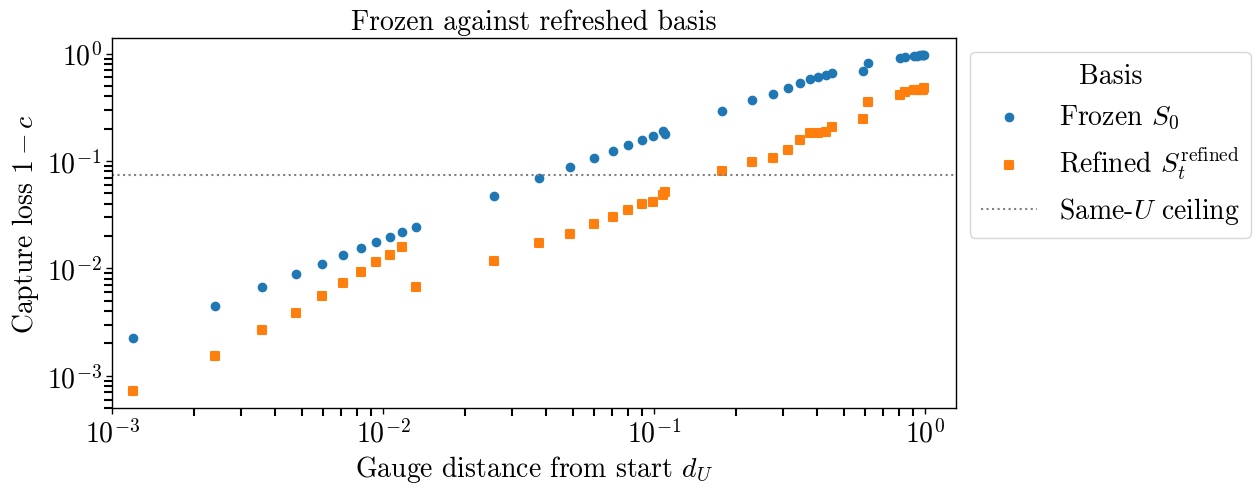

,dU,loss_f,loss_r,loss_s
trajL,,,,
0.03,0.0118,0.0216,0.0157,0.0022
0.10,0.1080,0.1882,0.0479,0.0250
0.30,0.4536,0.6661,0.2071,0.2049
1.00,0.9872,0.9741,0.4819,0.7576


In [8]:
post = data[~data["trajL"].isin(PRE_FIX)]

fig, ax = pt.add_subplots()
ax = ax[0]
labels = [r"Gauge distance from start $d_U$", r"Capture loss $1 - c$"]
pt.scatter_1d(post["dU"], post["loss_f"], ax=ax, col=RUNG_COLOR["(b) frozen S0"], mkr=RUNG_MARKER["(b) frozen S0"],
              fn_label=r"Frozen $S_0$", logx=True, logy=True, ax_label=labels)
pt.scatter_1d(post["dU"], post["loss_r"], ax=ax, col=RUNG_COLOR["(c) refined"], mkr=RUNG_MARKER["(c) refined"],
              fn_label=r"Refined $S_t^{\rm refined}$", logx=True, logy=True, ax_label=labels)
pt.add_line(ax, 1 - cap_other, orientation='h', c=REF_COLOR, linestyle=':', label='Same-$U$ ceiling')
ax.set_xlim(1e-3, 1.3)
pt.add_title(ax, r"Frozen against refreshed basis")
ax.legend(title="Basis", **LEGEND)
plt.show()

final_traj = post[post["traj"] == post["traj"].max()][["trajL", "dU", "loss_f", "loss_r", "loss_s"]]
final_traj.set_index("trajL").round(4)

- The refreshed basis stays well below the frozen one at every $\tau$; after 10 trajectories its loss is 0.016 against 0.022 at $\tau = 0.03$, 0.048 against 0.19 at $\tau = 0.1$, and 0.48 against 0.97 at $\tau = 1$.
- At $\tau = 0.3$, $1 - c_{\rm refined}$ (0.21) matches $1 - c_{\rm step}$ (0.20), the loss over a single trajectory: the pass recovers what earlier trajectories cost but stays about one trajectory behind. At $\tau = 1$ it does better than that (0.48 against 0.76 for one step). At small $\tau$ the refined loss still grows steadily, which I think reflects one pass at tolerance $10^{-2}$ converging only partly.
- Unlike the frozen basis, the refined points do **not** collapse onto one curve in $d_U$: at $d_U \approx 0.013$ the $\tau = 0.1$ run (one refresh) loses 0.007 while the $\tau = 0.03$ run (ten refreshes) loses 0.016. The refined loss depends on how many passes have been made, not only on how far $U$ has moved.

## 7. Does the MG solver see it?

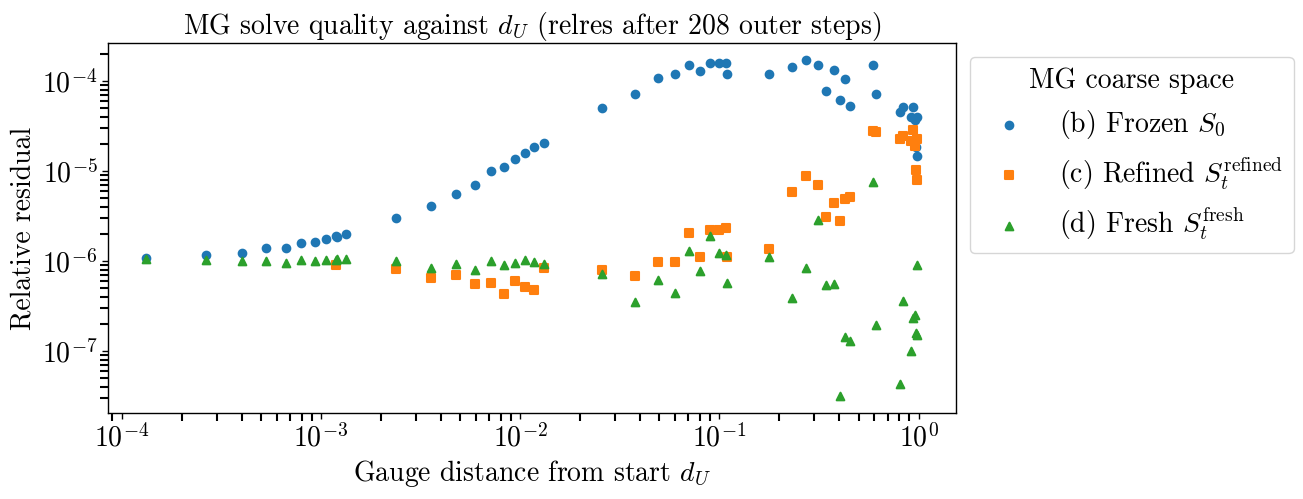

In [9]:
fig, ax = pt.add_subplots()
ax = ax[0]
series = [("(b) frozen S0", r"(b) Frozen $S_0$",                 data, "rb"),
          ("(c) refined",   r"(c) Refined $S_t^{\rm refined}$",  post, "rc"),
          ("(d) fresh",     r"(d) Fresh $S_t^{\rm fresh}$",      data, "rd")]
for name, label, df, col in series:
    pt.scatter_1d(df["dU"], df[col], ax=ax, col=RUNG_COLOR[name], mkr=RUNG_MARKER[name], fn_label=label,
                  logx=True, logy=True,
                  ax_label=[r"Gauge distance from start $d_U$", r"Relative residual"])
pt.add_title(ax, r"MG solve quality against $d_U$ (relres after 208 outer steps)")
ax.legend(title="MG coarse space", **LEGEND)
plt.show()

- **(d) fresh** stays at or below about $2 \times 10^{-6}$ throughout, so the baseline does not get worse with $d_U$. It scatters lower (down to $3 \times 10^{-8}$) at large $d_U$, where the plaquette is drifting; I don't know whether the relaxing configuration is simply easier to solve.
- **(b) frozen** degrades steadily with $d_U$: $2 \times 10^{-5}$ at $d_U \approx 0.01$ (capture loss 2%, already a factor of about 18 worse than fresh) and $1$–$2 \times 10^{-4}$ for $d_U$ between 0.05 and 0.3. Beyond that it scatters back down to $1.5 \times 10^{-5}$ at $d_U \approx 1$, which I can't explain from these data; with the frozen coarse space essentially random there, I'd guess the smoother is carrying those solves.
- **(c) refined** stays within a factor of about 2 of fresh up to $d_U \approx 0.1$ and degrades only at the largest displacements.
- Every solve hits the 208-step cap at $N = 8$, so these are residuals at fixed work, not iteration counts.

## 8. Why the global-span measurements looked uninformative at $\tau = 1$

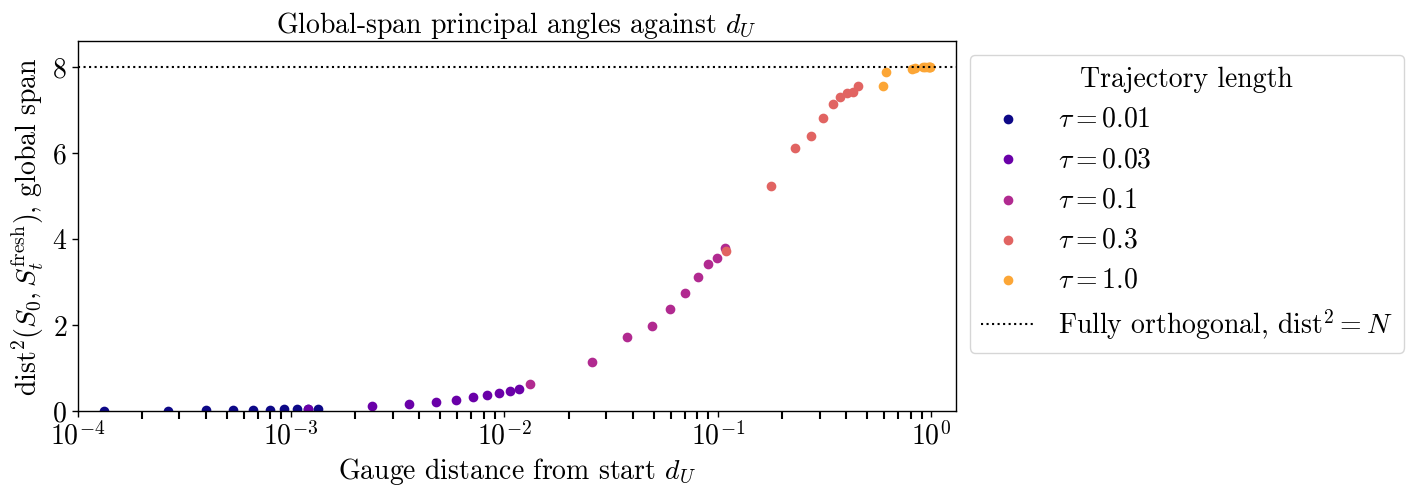

In [10]:
fig, ax = pt.add_subplots()
ax = ax[0]
for trajL, df in runs.items():
    pt.scatter_1d(df["dU"], df["d_flow"], ax=ax, col=TRAJL_COLOR[trajL], mkr='o',
                  fn_label=rf"$\tau = {trajL}$", logx=True,
                  ax_label=[r"Gauge distance from start $d_U$", r"$\mathrm{dist}^2(S_0, S_t^{\rm fresh})$, global span"])
pt.add_line(ax, nbasis, orientation='h', c='k', linestyle=':', label=r"Fully orthogonal, $\mathrm{dist}^2 = N$")
ax.set_xlim(1e-4, 1.3); ax.set_ylim(0, 8.6)
pt.add_title(ax, r"Global-span principal angles against $d_U$")
ax.legend(title="Trajectory length", **LEGEND)
plt.show()

The principal angles between global spans grow smoothly for $d_U \lesssim 0.05$ and are close to fully orthogonal ($\mathrm{dist}^2 \approx 7.5$ of 8) by $d_U \approx 0.4$. At $\tau = 1$ (job 424581, and 424796 here) a single trajectory is already past that point, which is why those runs showed every global measurement pinned at its maximum while the MG solves still worked: the block span keeps information the global span loses.

## 9. MD-step scan at $\tau = 1$: production-like acceptance

The sweep ran at $P_{\rm acc} \ge 0.9$. Production HMC runs at lower acceptance, so jobs 425356–425358 repeat the $\tau = 1$ run with fewer MD steps (larger $\delta\tau$). Everything else, including the seeds, is unchanged.

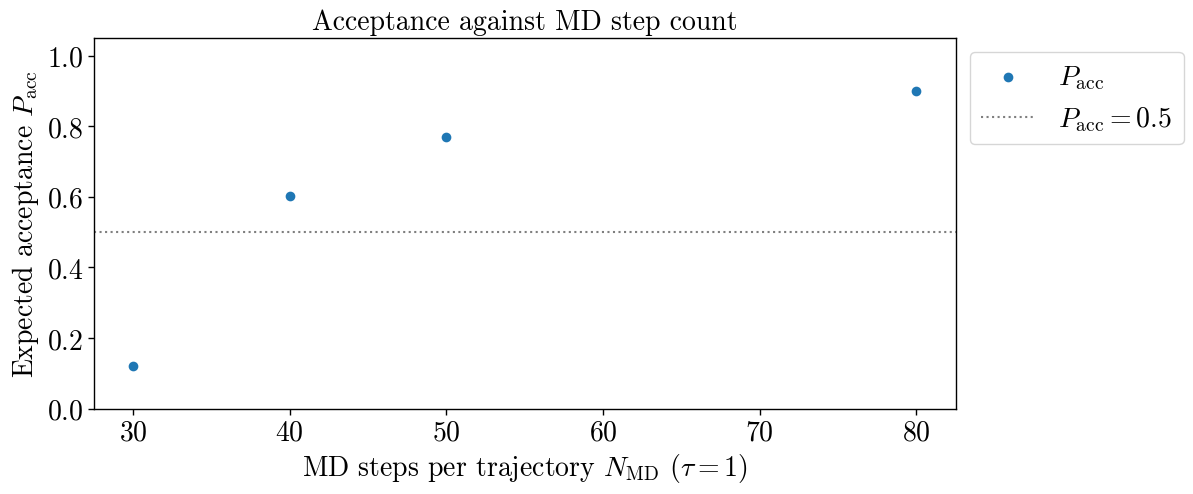

,accepted,P_acc,<dH>,plaquette t=10
N_MD,,,,
30,0/10,0.122055,2.150904,0.587686
40,8/10,0.602312,0.570102,0.579976
50,9/10,0.770773,0.284216,0.580302
80,10/10,0.901250,0.105710,0.579622


In [11]:
acc_table = pd.DataFrame({
    "accepted": [f'{int(df["accepted"].sum())}/{len(df)}' for df in scan.values()],
    "P_acc":    [np.minimum(1.0, np.exp(-df["dH"])).mean() for df in scan.values()],
    "<dH>":     [df["dH"].mean() for df in scan.values()],
    "plaquette t=10": [df["plaq"].iloc[-1] for df in scan.values()],
}, index=pd.Index(list(scan), name="N_MD")).sort_index()

fig, ax = pt.add_subplots()
ax = ax[0]
pt.scatter_1d(acc_table.index, acc_table["P_acc"], ax=ax, col=pt.pal[0], mkr='o', fn_label=r"$P_{\rm acc}$",
              ax_label=[r"MD steps per trajectory $N_{\rm MD}$ ($\tau = 1$)", r"Expected acceptance $P_{\rm acc}$"])
pt.add_line(ax, 0.5, orientation='h', c=REF_COLOR, linestyle=':', label=r"$P_{\rm acc} = 0.5$")
ax.set_ylim(0, 1.05)
pt.add_title(ax, r"Acceptance against MD step count")
ax.legend(**LEGEND)
plt.show()
acc_table

$N_{\rm MD} = 40$ gives $P_{\rm acc} \approx 0.6$ and is the setting chosen for the MG-HMC runs (jobs 425415–425418). At $N_{\rm MD} = 30$ every trajectory was rejected, so $U$ never left $U_0$ in that run. $\Delta H$ falls along the $N_{\rm MD} = 40$ and 50 runs as the plaquette relaxes towards the quenched value, so I expect equilibrium acceptance at 40 steps to sit nearer 0.7 than 0.6.

**Does staleness depend on the step size?** The plot below overlays the frozen-basis loss for the three runs that moved, against $d_U$.

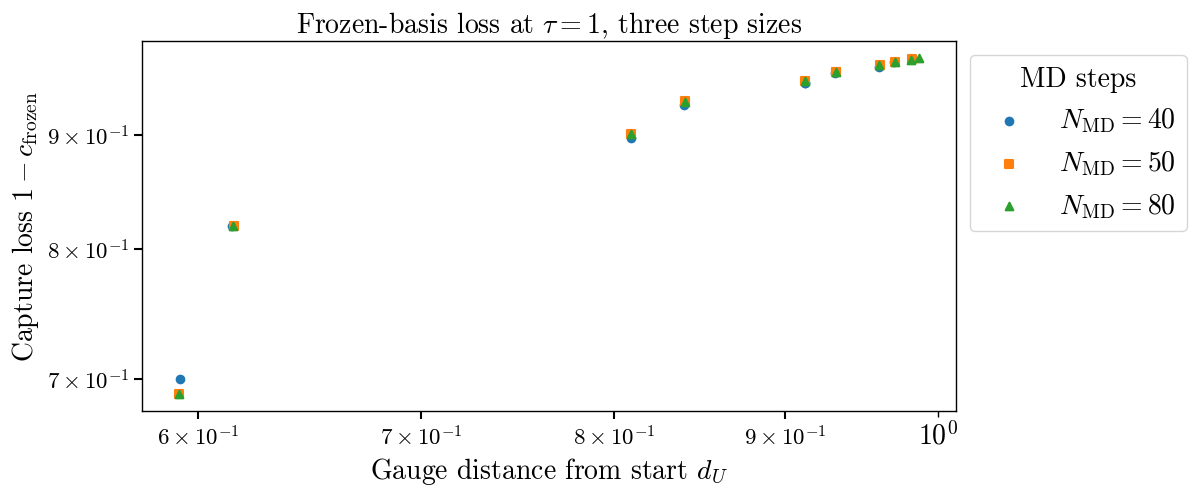

In [12]:
fig, ax = pt.add_subplots()
ax = ax[0]
for i, n_md in enumerate([40, 50, 80]):
    moved = scan[n_md][scan[n_md]["dU"] > 0]
    pt.scatter_1d(moved["dU"], moved["loss_f"], ax=ax, col=pt.pal[i], mkr=['o', 's', '^'][i],
                  fn_label=rf"$N_{{\rm MD}} = {n_md}$", logx=True, logy=True,
                  ax_label=[r"Gauge distance from start $d_U$", r"Capture loss $1 - c_{\rm frozen}$"])
pt.add_title(ax, r"Frozen-basis loss at $\tau = 1$, three step sizes")
ax.legend(title="MD steps", **LEGEND)
plt.show()

The three step sizes give the same $d_U$ per trajectory ($\approx 0.59$ for the first accepted trajectory) and the same capture loss at matching $d_U$ (0.689 at $d_U = 0.592$ for both 50 and 80 steps). Staleness is set by how far $U$ moves, which at fixed $\tau$ is fixed by the momenta, not by the integrator's step size. All these points sit in the saturated regime of section 4, so the scan adds no information about the linear law; it shows that moving to production-like acceptance does not change the picture.

**A fixed-$U$ control, by accident.** Because the $N_{\rm MD} = 30$ run rejected every trajectory, its rung (c) repeated the sloppy refresh ten times on the same $U_0$.

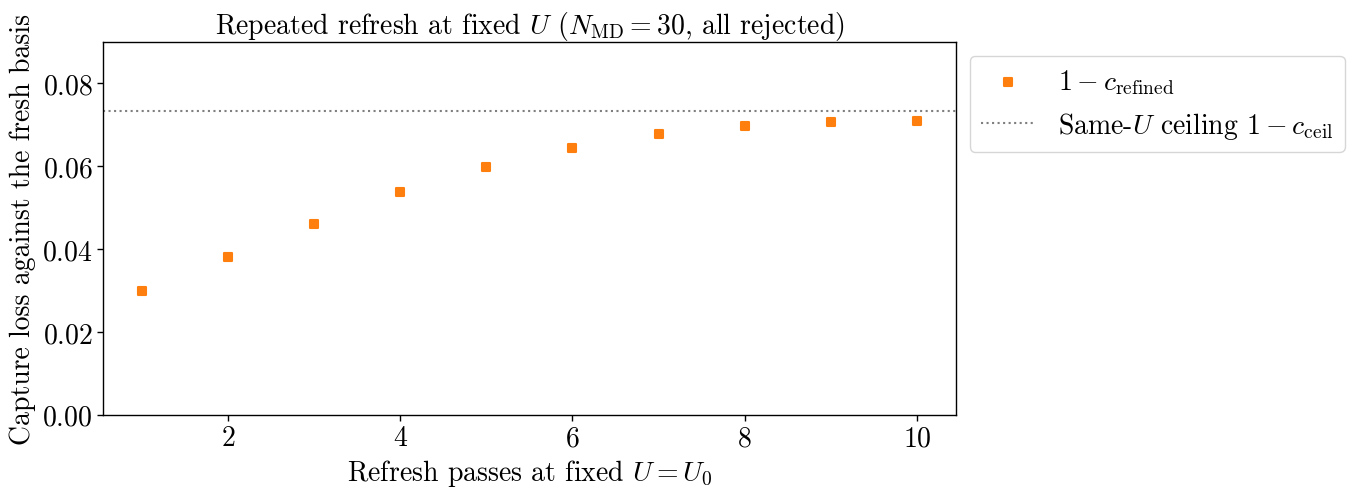

,traj,dU,loss_r,rb,rc,rd
0,1,0.0,0.029906,0.000001,0.000001,0.000001
1,2,0.0,0.038011,0.000001,0.000001,0.000001
2,3,0.0,0.045931,0.000001,0.000001,0.000001
3,4,0.0,0.053721,0.000001,0.000001,0.000001
4,5,0.0,0.059763,0.000001,0.000001,0.000001
5,6,0.0,0.064418,0.000001,0.000001,0.000001
6,7,0.0,0.067667,0.000001,0.000002,0.000001
7,8,0.0,0.069694,0.000001,0.000002,0.000001
8,9,0.0,0.070679,0.000001,0.000002,0.000001
9,10,0.0,0.070961,0.000001,0.000002,0.000001


In [13]:
fixed = scan[30]
fig, ax = pt.add_subplots()
ax = ax[0]
pt.scatter_1d(fixed["traj"], fixed["loss_r"], ax=ax, col=pt.pal[1], mkr='s', fn_label=r"$1 - c_{\rm refined}$",
              ax_label=[r"Refresh passes at fixed $U = U_0$", r"Capture loss against the fresh basis"])
pt.add_line(ax, 1 - cap_other, orientation='h', c=REF_COLOR, linestyle=':', label=r"Same-$U$ ceiling $1 - c_{\rm ceil}$")
ax.set_ylim(0, 0.09)
pt.add_title(ax, r"Repeated refresh at fixed $U$ ($N_{\rm MD} = 30$, all rejected)")
ax.legend(**LEGEND)
plt.show()
fixed[["traj", "dU", "loss_r", "rb", "rc", "rd"]]

With $U$ fixed, the refined basis still moves away from the same-noise fresh basis, from a loss of 0.030 after one pass to 0.071 after ten, flattening at the same-$U$ ceiling $1 - c_{\rm ceil} = 0.073$: the loss a basis bred from *different* noise shows at the same $U$. Its MG solves stay at fresh-basis quality throughout (relres $1.2$–$1.9 \times 10^{-6}$ against $1.1 \times 10^{-6}$). So repeated refreshing converges to a different, equally valid near-null basis rather than going stale. Consequently $1 - c_{\rm refined}$ in section 6 has a floor of about 0.07 that has nothing to do with $U$ changing, and rung (c) is better than that comparison makes it look.

## 10. Conclusions

1. Frozen-basis staleness is a function of $d_U$ alone over the sweep: $1 - c_{\rm frozen} \approx 1.8\, d_U$ up to $d_U \approx 0.05$, bending over and saturating near 1 beyond. Reusing a basis across full $\tau = 1$ trajectories does not work in this setup; one trajectory loses about 70%.
2. One trajectory moves $U$ by $\Delta d_U \propto \tau^2$. If that ballistic scaling holds *within* a trajectory, which is what the across-run scaling suggests but was not measured directly, then consecutive force evaluations at $\delta\tau = 1/80$ differ by $d_U \approx 2 \times 10^{-4}$ (scaling $\Delta d_U$ at $\tau = 0.01$ by $\tau^2$), a capture loss of about $4 \times 10^{-4}$. **Updating the basis along the trajectory looks cheap; carrying it across trajectories does not.**
3. A single sloppy inverse-iteration pass per trajectory recovers most of the loss and keeps the MG solve at fresh-setup quality up to $d_U \approx 0.1$.
4. The MG residual follows the block-span capture, so capture is a usable proxy for preconditioner quality: about 2% loss already costs an order of magnitude in residual at fixed work.
5. Global-span measurements ($\theta_k$, $\eta$) are informative only for $d_U \lesssim 0.05$ and are the wrong object for MG, whose coarse space is the block span.
6. At production-like acceptance ($N_{\rm MD} = 40$, $P_{\rm acc} \approx 0.6$) nothing changes: the capture loss depends on $d_U$, not on the MD step size.
7. Comparing a refreshed basis with a same-noise fresh one has a floor of about 0.07 even at fixed $U$: repeated refreshing drifts to a different valid near-null basis, as far from the fresh one as a basis bred from different noise.

## 11. Caveats

- One configuration, one noise seed for the reference basis (apart from the $U_0$ ceiling), $N = 8$.
- Quenched Iwasaki dynamics at a guessed $\beta = 2.13$; the action that generated `ckpoint_lat.4000` has not been established. For $\tau \ge 0.3$ the plaquette drifts, so those runs mix relaxation with fluctuation.
- **$d_U$ is not gauge invariant.** Because the action is gauge invariant, I believe the component of the momentum along gauge orbits is conserved and $U$ drifts along the orbit ballistically. Under $U \to U^g$ the near-null vectors rotate as $v \to g\, v$, which takes them out of $\mathcal{B}(S_0)$ whenever $g$ varies within a block. Some of the capture loss may therefore be physically empty gauge motion, and $d_U$ counts it.
- The ceiling $c_{\rm ceil}$ was measured only at $U_0$.

## 12. Next steps

1. **Gauge-drift test.** Gauge-fix $U_t$ relative to $U_0$ (maximise $\mathrm{Re}\,\mathrm{tr}(U_0^\dagger U_t^g)$), or Landau-fix both, and re-measure $c_{\rm frozen}$ against a gauge-invariant displacement. If most of the loss disappears, staleness is mostly gauge drift and the cheap fix is to transport the basis, $v \to g\, v$.
2. **Perturbative update using the MG solver.** First-order correction $\psi \to \psi - A^{-1} P_\perp (\delta A)\, \psi$, with $\delta A$ known analytically from the MD update and the solve preconditioned by the stale MG. For a pure-gauge $\delta A$ this correction is exactly a local gauge rotation of $\psi$, so it should handle the drift of caveat 3 automatically.